# 00 — Primeiro contato com os dados

**Projeto Respira** — estimativa de nível de ansiedade a partir de hábitos e sinais vitais
Entrega 1 · Dataset: *Social Anxiety Dataset* (Kaggle, licença CC0)

O que este notebook faz:

1. carrega o arquivo e mostra o que veio (linhas, colunas, tipos, nulos);
2. investiga a distribuição do alvo e a relação dele com cada variável;
3. checa se o dado é real ou gerado, e o que isso implica;
4. roda os três baselines e mede MAE e R² de cada um.

---
## 1. Setup

In [ ]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)

SEED = 42
ALVO = "Anxiety Level (1-10)"
print("pandas", pd.__version__)

pandas 2.2.3


---
## 2. Carregar

**No Colab:** a célula abre um botão de upload. Escolha o `enhanced_anxiety_dataset.csv`.
**Local:** coloque o arquivo em `data/raw/`.

In [ ]:
NOME = "enhanced_anxiety_dataset.csv"
CANDIDATOS = [f"../data/raw/{NOME}", f"data/raw/{NOME}", NOME, f"/content/{NOME}"]
CAMINHO = next((c for c in CANDIDATOS if os.path.exists(c)), None)

if CAMINHO is None:
    try:
        from google.colab import files
        print(f"Selecione o arquivo {NOME}:")
        CAMINHO = list(files.upload().keys())[0]
    except ImportError:
        raise FileNotFoundError(f"{NOME} nao encontrado. Coloque em data/raw/.")

print("Lendo:", CAMINHO)
df = pd.read_csv(CAMINHO)
print("Shape:", df.shape)
df.head()

Selecione o arquivo enhanced_anxiety_dataset.csv:


Saving enhanced_anxiety_dataset.csv to enhanced_anxiety_dataset.csv
Lendo: enhanced_anxiety_dataset.csv
Shape: (11000, 19)


,Age,Gender,Occupation,Sleep Hours,Physical Activity (hrs/week),Caffeine Intake (mg/day),Alcohol Consumption (drinks/week),Smoking,Family History of Anxiety,Stress Level (1-10),Heart Rate (bpm),Breathing Rate (breaths/min),Sweating Level (1-5),Dizziness,Medication,Therapy Sessions (per month),Recent Major Life Event,Diet Quality (1-10),Anxiety Level (1-10)
0,29,Female,Artist,6.0,2.7,181,10,Yes,No,10,114,14,4,No,Yes,3,Yes,7,5.0
1,46,Other,Nurse,6.2,5.7,200,8,Yes,Yes,1,62,23,2,Yes,No,2,No,8,3.0
2,64,Male,Other,5.0,3.7,117,4,No,Yes,1,91,28,3,No,No,1,Yes,1,1.0
3,20,Female,Scientist,5.8,2.8,360,6,Yes,No,4,86,17,3,No,No,0,No,1,2.0
4,49,Female,Other,8.2,2.3,247,4,Yes,No,1,98,19,4,Yes,Yes,1,No,3,1.0


---
## 3. O que veio no arquivo

In [ ]:
LINHAS, COLUNAS = df.shape

print("=" * 78)
print(f"LINHAS x COLUNAS: {LINHAS:,} x {COLUNAS}")
print("=" * 78)
for c in df.columns:
    marca = "  <-- ALVO" if c == ALVO else ""
    print(f"  {c:36s} {str(df[c].dtype):8s} "
          f"nulos: {df[c].isna().sum():>4}  distintos: {df[c].nunique():>5}{marca}")

print(f"\nNulos no total : {df.isna().sum().sum()}")
print(f"Linhas duplicadas: {df.duplicated().sum()}")

LINHAS x COLUNAS: 11,000 x 19
  Age                                  int64    nulos:    0  distintos:    47
  Gender                               object   nulos:    0  distintos:     3
  Occupation                           object   nulos:    0  distintos:    13
  Sleep Hours                          float64  nulos:    0  distintos:    82
  Physical Activity (hrs/week)         float64  nulos:    0  distintos:   100
  Caffeine Intake (mg/day)             int64    nulos:    0  distintos:   600
  Alcohol Consumption (drinks/week)    int64    nulos:    0  distintos:    20
  Smoking                              object   nulos:    0  distintos:     2
  Family History of Anxiety            object   nulos:    0  distintos:     2
  Stress Level (1-10)                  int64    nulos:    0  distintos:    10
  Heart Rate (bpm)                     int64    nulos:    0  distintos:    60
  Breathing Rate (breaths/min)         int64    nulos:    0  distintos:    18
  Sweating Level (1-5)            

In [ ]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,11000.0,40.24,13.24,18.0,29.0,40.0,51.0,64.0
Sleep Hours,11000.0,6.65,1.23,2.3,5.9,6.7,7.5,11.3
Physical Activity (hrs/week),11000.0,2.94,1.83,0.0,1.5,2.8,4.2,10.1
Caffeine Intake (mg/day),11000.0,286.09,144.81,0.0,172.0,273.0,382.0,599.0
Alcohol Consumption (drinks/week),11000.0,9.70,5.69,0.0,5.0,10.0,15.0,19.0
Stress Level (1-10),11000.0,5.86,2.93,1.0,3.0,6.0,8.0,10.0
Heart Rate (bpm),11000.0,90.92,17.33,60.0,76.0,92.0,106.0,119.0
Breathing Rate (breaths/min),11000.0,20.96,5.16,12.0,17.0,21.0,25.0,29.0
Sweating Level (1-5),11000.0,3.08,1.40,1.0,2.0,3.0,4.0,5.0
Therapy Sessions (per month),11000.0,2.43,2.18,0.0,1.0,2.0,4.0,12.0


### Dado real ou gerado?

Zero nulos, zero duplicadas e nenhum valor impossível em 11 mil linhas **não acontece** em dado coletado de gente de verdade. Pesquisa real tem pergunta em branco, idade digitada errada e resposta repetida.

A conclusão, que vai documentada no README: este é um dataset **sintético**, gerado a partir de regras. Isso não invalida o trabalho — a modelagem, a validação e a análise de erro são as mesmas — mas significa que o modelo aprende o **gerador**, não a ansiedade. Nenhuma conclusão daqui vale como achado clínico.

In [ ]:
# As categoricas
for c in df.select_dtypes(include=["object", "string"]).columns:
    vc = df[c].value_counts()
    print(f"{c}  ({df[c].nunique()} categorias)")
    print("   " + " | ".join(f"{k}: {v}" for k, v in vc.head(6).items()))
    print()

Gender  (3 categorias)
   Female: 3730 | Male: 3657 | Other: 3613

Occupation  (13 categorias)
   Musician: 892 | Artist: 888 | Student: 878 | Nurse: 861 | Chef: 858 | Doctor: 842

Smoking  (2 categorias)
   Yes: 5779 | No: 5221

Family History of Anxiety  (2 categorias)
   Yes: 5847 | No: 5153

Dizziness  (2 categorias)
   Yes: 5672 | No: 5328

Medication  (2 categorias)
   Yes: 5666 | No: 5334

Recent Major Life Event  (2 categorias)
   Yes: 5623 | No: 5377



---
## 4. O alvo

count    11000.00
mean         3.93
std          2.12
min          1.00
25%          2.00
50%          4.00
75%          5.00
max         10.00

Distribuicao:
Anxiety Level (1-10)
1.0     1039
2.0     1756
3.0     2407
4.0     2416
5.0     1629
6.0      616
7.0      123
8.0      363
9.0      329
10.0     322


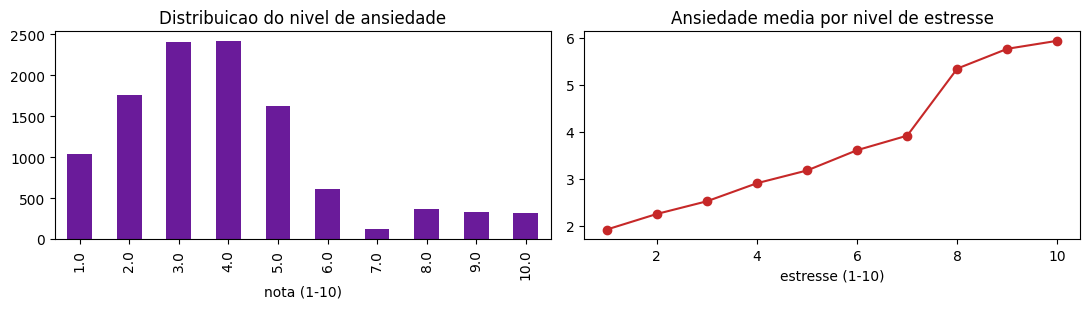

In [ ]:
print(df[ALVO].describe().round(2).to_string())
print()
print("Distribuicao:")
print(df[ALVO].value_counts().sort_index().to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
df[ALVO].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#6A1B9A")
axes[0].set_title("Distribuicao do nivel de ansiedade")
axes[0].set_xlabel("nota (1-10)")

df.groupby("Stress Level (1-10)")[ALVO].mean().plot(marker="o", ax=axes[1], color="#C62828")
axes[1].set_title("Ansiedade media por nivel de estresse")
axes[1].set_xlabel("estresse (1-10)")
plt.tight_layout()
plt.show()

Correlacao de cada variavel numerica com o alvo:
Stress Level (1-10)                  0.668
Therapy Sessions (per month)         0.518
Sleep Hours                         -0.494
Caffeine Intake (mg/day)             0.351
Physical Activity (hrs/week)        -0.243
Diet Quality (1-10)                 -0.220
Heart Rate (bpm)                     0.189
Sweating Level (1-5)                 0.160
Breathing Rate (breaths/min)         0.157
Alcohol Consumption (drinks/week)    0.101
Age                                 -0.074


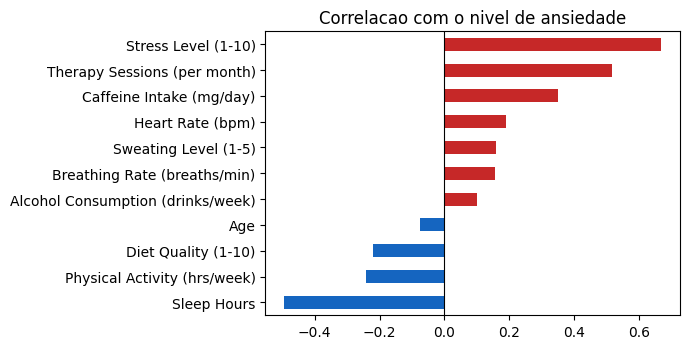

In [ ]:
num = df.select_dtypes(include=[np.number])
corr = num.corr()[ALVO].drop(ALVO).sort_values(key=abs, ascending=False)

print("Correlacao de cada variavel numerica com o alvo:")
print(corr.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 3.6))
corr.sort_values().plot(kind="barh", ax=ax,
                        color=["#1565C0" if v < 0 else "#C62828" for v in corr.sort_values()])
ax.set_title("Correlacao com o nivel de ansiedade")
ax.axvline(0, color="black", lw=0.8)
plt.tight_layout()
plt.show()

### Causalidade reversa

`Therapy Sessions (per month)` e `Medication` aparecem associadas a ansiedade **mais alta**. A leitura ingênua ("terapia faz mal") é absurda: quem faz terapia e toma remédio é justamente quem já tem ansiedade alta. São **consequência**, não causa.

Isso não é vazamento no sentido estrito — no momento do formulário a pessoa sabe se faz terapia — mas distorce qualquer interpretação de "fatores de risco". A célula abaixo mede quanto do desempenho depende dessas duas.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

def prep(d, drop=()):
    X = pd.get_dummies(d.drop(columns=[ALVO] + list(drop)), drop_first=True)
    return X, d[ALVO]

for drop, rotulo in [((), "com todas as variaveis"),
                     (("Therapy Sessions (per month)", "Medication"), "sem terapia e medicacao")]:
    X, y = prep(df, drop)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)
    p = HistGradientBoostingRegressor(random_state=SEED).fit(Xtr, ytr).predict(Xte)
    print(f"{rotulo:28s} MAE={mean_absolute_error(yte, p):.3f}  R2={r2_score(yte, p):.3f}")

print("\n>>> Se a queda for pequena, o modelo nao depende dessas duas variaveis.")

com todas as variaveis       MAE=0.818  R2=0.779
sem terapia e medicacao      MAE=0.829  R2=0.771

>>> Se a queda for pequena, o modelo nao depende dessas duas variaveis.


---
## 5. Baselines

Três referências. Um modelo só se justifica se superar as três.

| | Regra |
|---|---|
| **B0** | prever sempre a média do treino |
| **B1** | copiar o nível de estresse — as duas escalas vão de 1 a 10 |
| **B2** | regressão linear com uma única variável: estresse |

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

X, y = prep(df)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Treino: {len(X_tr):,}   Teste: {len(X_te):,}")

resultados = []

def avaliar(nome, pred):
    resultados.append({
        "baseline": nome,
        "MAE": mean_absolute_error(y_te, pred),
        "RMSE": mean_squared_error(y_te, pred) ** 0.5,
        "R2": r2_score(y_te, pred),
    })

# B0 - media do treino
avaliar("B0 - media do treino", np.full(len(y_te), y_tr.mean()))

# B1 - copiar o estresse
avaliar("B1 - copiar o estresse", X_te["Stress Level (1-10)"].values.astype(float))

# B2 - linear so com estresse
lr1 = LinearRegression().fit(X_tr[["Stress Level (1-10)"]], y_tr)
avaliar("B2 - linear so com estresse", lr1.predict(X_te[["Stress Level (1-10)"]]))

# Modelos de referencia
avaliar("Regressao linear completa", LinearRegression().fit(X_tr, y_tr).predict(X_te))
avaliar("Gradient boosting",
        HistGradientBoostingRegressor(random_state=SEED).fit(X_tr, y_tr).predict(X_te))

res = pd.DataFrame(resultados).set_index("baseline").round(4)
res

Treino: 8,800   Teste: 2,200


,MAE,RMSE,R2
baseline,,,
B0 - media do treino,1.6052,2.1527,-0.0001
B1 - copiar o estresse,2.3568,2.9590,-0.8896
B2 - linear so com estresse,1.2211,1.6162,0.4363
Regressao linear completa,0.8921,1.1259,0.7264
Gradient boosting,0.8182,1.0121,0.7789


### Leitura

- **B0** tem R² igual a zero por definição: prever a média não explica variação nenhuma. O MAE dele é a régua — é o erro de quem não tem modelo.
- **B1** testa a hipótese preguiçosa "ansiedade é a mesma coisa que estresse". Atenção ao resultado: ele costuma ficar **pior que B0**, porque as duas escalas vão de 1 a 10 mas têm médias diferentes — copiar o valor erra por deslocamento. É um baseline que falha de um jeito informativo.
- **B2** mostra quanto uma única variável explica quando bem calibrada.
- O ganho do modelo completo sobre B2 é o que **as outras 17 variáveis acrescentam**.

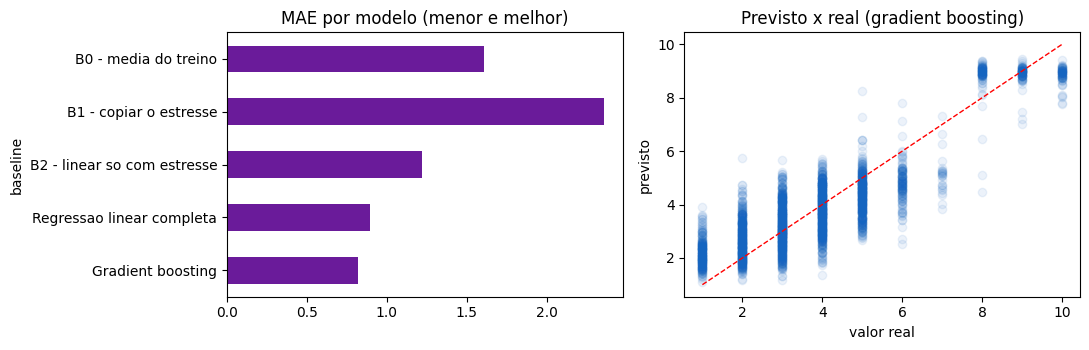

Erro medio  : +0.029 (vies)
Erro absoluto medio: 0.818 pontos na escala de 1 a 10
Pior erro   : 3.74 pontos


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

res["MAE"].plot(kind="barh", ax=axes[0], color="#6A1B9A")
axes[0].set_title("MAE por modelo (menor e melhor)")
axes[0].invert_yaxis()

melhor = HistGradientBoostingRegressor(random_state=SEED).fit(X_tr, y_tr).predict(X_te)
axes[1].scatter(y_te, melhor, alpha=0.08, color="#1565C0")
axes[1].plot([1, 10], [1, 10], "r--", lw=1)
axes[1].set_xlabel("valor real")
axes[1].set_ylabel("previsto")
axes[1].set_title("Previsto x real (gradient boosting)")

plt.tight_layout()
plt.show()

erro = melhor - y_te.values
print(f"Erro medio  : {erro.mean():+.3f} (vies)")
print(f"Erro absoluto medio: {np.abs(erro).mean():.3f} pontos na escala de 1 a 10")
print(f"Pior erro   : {np.abs(erro).max():.2f} pontos")

---
## 6. Resumo da entrega

In [ ]:
print("=" * 72)
print("NUMEROS DA ENTREGA 1")
print("=" * 72)
print(f"Linhas x colunas     : {LINHAS:,} x {COLUNAS}")
print(f"Nulos / duplicadas   : {df.isna().sum().sum()} / {df.duplicated().sum()}")
print(f"Alvo                 : {ALVO}  (de {df[ALVO].min():.0f} a {df[ALVO].max():.0f}, "
      f"media {df[ALVO].mean():.2f})")
print(f"Variaveis de entrada : {COLUNAS - 1}")
print()
for nome, r in res.iterrows():
    print(f"  {nome:28s} MAE={r['MAE']:.3f}  RMSE={r['RMSE']:.3f}  R2={r['R2']:.3f}")
print()
bases = ["B0 - media do treino", "B1 - copiar o estresse", "B2 - linear so com estresse"]
melhor_base = res.loc[bases, "MAE"].idxmin()
ganho = res.loc[melhor_base, "MAE"] - res.loc["Gradient boosting", "MAE"]
print(f">>> Melhor baseline: {melhor_base} (MAE={res.loc[melhor_base, 'MAE']:.3f})")
print(f">>> O modelo reduz o erro em {ganho:.3f} ponto frente a ele.")
print("=" * 72)

NUMEROS DA ENTREGA 1
Linhas x colunas     : 11,000 x 19
Nulos / duplicadas   : 0 / 0
Alvo                 : Anxiety Level (1-10)  (de 1 a 10, media 3.93)
Variaveis de entrada : 18

  B0 - media do treino         MAE=1.605  RMSE=2.153  R2=-0.000
  B1 - copiar o estresse       MAE=2.357  RMSE=2.959  R2=-0.890
  B2 - linear so com estresse  MAE=1.221  RMSE=1.616  R2=0.436
  Regressao linear completa    MAE=0.892  RMSE=1.126  R2=0.726
  Gradient boosting            MAE=0.818  RMSE=1.012  R2=0.779

>>> Melhor baseline: B2 - linear so com estresse (MAE=1.221)
>>> O modelo reduz o erro em 0.403 ponto frente a ele.


---
## Próximos passos (E2)

- Validação cruzada em 5 partições em vez de uma única divisão, para medir a variância do resultado.
- Ajuste de hiperparâmetros do gradient boosting.
- Analisar os erros maiores: são as notas altas (8 a 10), que são raras? Se sim, vale pesar essas observações.
- Decidir se `Therapy Sessions` e `Medication` ficam no modelo final. Elas ajudam pouco e atrapalham a interpretação como fatores de risco.
- Verificar se o erro é maior em algum subgrupo (gênero, ocupação).